# Statistics 4: Continuous distributions

*Learning path: probability and statistics, part 4 of 8.* [Index](README.md) · Previous: [Discrete distributions](03-discrete-distributions.ipynb) · Next: [Sampling and the central limit theorem](05-sampling-and-clt.ipynb)

What is the probability that a randomly chosen adult is exactly 170 cm tall? Not "170 to the nearest centimetre", but
170.000... exactly. The answer is zero, and yet heights near 170 are common. Measurements such as heights, waiting
times and lifetimes take a continuum of values, and their probabilities live in **intervals**, not points. This lesson
replaces the bars of [lesson 3](03-discrete-distributions.ipynb) by a curve, the **density**, and the sums by
integrals. It ends with the bell curve and the 68-95-99.7 rule from [lesson 1](01-describing-data.ipynb).

**Who this is for.** You have done lesson 3 and know what a definite integral computes: the area under a curve.

**What you will be able to do afterwards:**

1. compute probabilities as areas under a density, and check that the total area is 1;
2. work with the uniform, exponential and normal distributions;
3. compute the mean and variance of a density by integration;
4. standardize a normal value and find probabilities and percentiles with `normcdf` and `norminv`.

Plan about an hour.

## 1. From histogram to density

In lesson 1 we drew a histogram of heights with counts on the vertical axis. Scale the bars so that their total area
is 1 (the `"density"` option of `hist`) and they settle onto a smooth curve as the number of values grows:

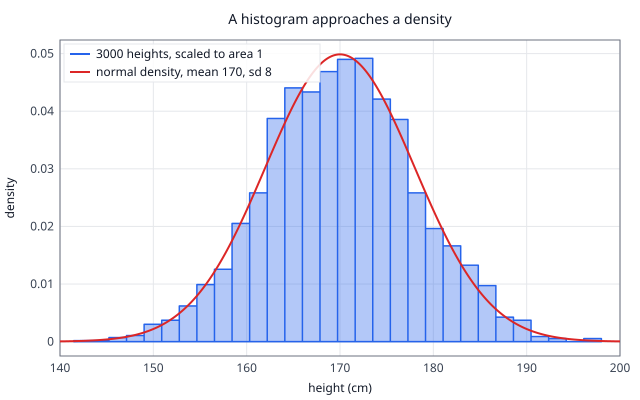

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [1]:
seed(2026);
h = 170 + 8*randn(1, 3000);
p = hist(h, 30, "density");
p = show(p, plot(normpdf(x, 170, 8), x, 140, 200));
p = legend(p, "3000 heights, scaled to area 1", "normal density, mean 170, sd 8");
labels(title(p, "A histogram approaches a density"), "height (cm)", "density")

That curve is a **probability density** $f(x)$. It is never negative, the total area under it is 1, and the
probability of an interval is the area over it:

$$P(a \le X \le b) = \int_a^b f(x)\,dx.$$

A single point has no width, so $P(X = 170) = 0$: only intervals have probability.

**Try this.** What fraction of the simulated heights lies between 160 and 180? Use `sum(abs(h - 170) < 10)/3000`, and
compare with `eval(normcdf(180, 170, 8) - normcdf(160, 170, 8))`.

## 2. The uniform distribution

The simplest density is flat: a number chosen "at random" between $a$ and $b$ has $f(x) = 1/(b - a)$ there and 0
elsewhere. `rand` gives uniform numbers between 0 and 1, and the probability of an interval is its length:

In [2]:
integrate(1/(b - a), x, a, b)
seed(3);
u = rand(1, 10000);
sum(u < 0.3)/10000

1

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

1491/5000

The **mean** of a density is $\mu = \int x f(x)\,dx$, the balance point of the area, and the **variance** is
$\sigma^2 = \int (x - \mu)^2 f(x)\,dx$, as in lesson 3 with integrals in place of sums. For the uniform distribution
the mean is the midpoint:

In [3]:
integrate(x/(b - a), x, a, b)
integrate((x - 1/2)^2, x, 0, 1)
[eval(mean(u)), eval(var(u))]

(a+b)/2

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

1/12

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

[0.49668381001357886, 0.0818560094402975]

The variance on $[0, 1]$ is $1/12 \approx 0.0833$; the 10,000 simulated values give 0.0819.

**Try this.** A bus comes every 10 minutes and you arrive at a random moment. What is the probability that you wait
more than 7 minutes? What is your mean wait?

## 3. The exponential distribution: waiting and lifetimes

Light bulbs of a certain kind last 1000 hours on average. If a bulb does not age (it is as good as new until the
moment it fails), its lifetime has the **exponential density** with mean $1000$:

$$f(x) = \frac{1}{1000}e^{-x/1000}, \qquad x \ge 0.$$

Check the total area and the mean, and find the probability that a bulb fails within 500 hours:

In [4]:
f = exp(-x/1000)/1000;
integrate(f, x, 0, inf)
integrate(x*f, x, 0, inf)
integrate(f, x, 0, 500)
eval(integrate(f, x, 0, 500))

1

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

1000

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

(sqrt(e)-1)/sqrt(e)

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

0.39346934028736663

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

39% of bulbs fail before 500 hours, $1 - e^{-1/2}$. The "does not age" assumption has a striking consequence, the
**memoryless property**: a bulb that has already lasted 1000 hours survives 500 more with the same probability as a new
bulb survives its first 500:

In [5]:
integrate(f, x, 1500, inf)/integrate(f, x, 1000, inf)
integrate(f, x, 500, inf)

1/sqrt(e)

1/sqrt(e)

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

Both are $e^{-1/2}$. To simulate exponential lifetimes, take $-1000 \log U$ for uniform $U$ (the probability that this
exceeds $x$ is the probability that $U < e^{-x/1000}$, which is $e^{-x/1000}$):

1013.7669184286794

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

696.7945450631142

> Median: the middle value after sorting (the average of the two middle values when the count is even). Half the data lie below it, half above; unlike the mean it ignores how extreme the extremes are.

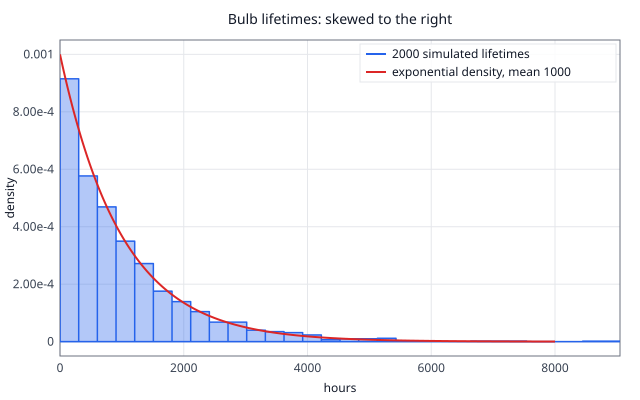

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
seed(11);
t = -1000*log(rand(1, 2000));
eval(mean(t))
median(t)
p = hist(t, 30, "density");
p = show(p, plot(f, x, 0, 8000));
p = legend(p, "2000 simulated lifetimes", "exponential density, mean 1000");
labels(title(p, "Bulb lifetimes: skewed to the right"), "hours", "density")

The distribution is skewed to the right, so the median (697 hours in the simulation, $1000 \log 2 \approx 693$ exactly)
is well below the mean of 1000. Half the bulbs fail before 693 hours, even though the average is 1000.

**Try this.** Compute the exact median by solving $\int_0^m f\,dx = 1/2$: `solve(1 - exp(-m/1000) == 1/2, m)`.

## 4. The normal distribution

The **normal** (or Gaussian) density with mean $\mu$ and standard deviation $\sigma$ is the bell curve

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\, e^{-(x - \mu)^2/(2\sigma^2)}.$$

It describes heights, measurement errors and, as [lesson 5](05-sampling-and-clt.ipynb) will show, averages of almost
anything. The **standard normal** has $\mu = 0$, $\sigma = 1$:

In [7]:
normpdf(x)
integrate(normpdf(x), x, -inf, inf)
integrate(x^2*normpdf(x), x, -inf, inf)

exp(-x^2/2)/(sqrt(2)*sqrt(pi))

> Normal density exp(−(x − μ)²/(2σ²))/(σ√(2π)).

1

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

1

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

Total area 1 and variance 1. Changing $\mu$ slides the curve; changing $\sigma$ stretches it, keeping the area 1:

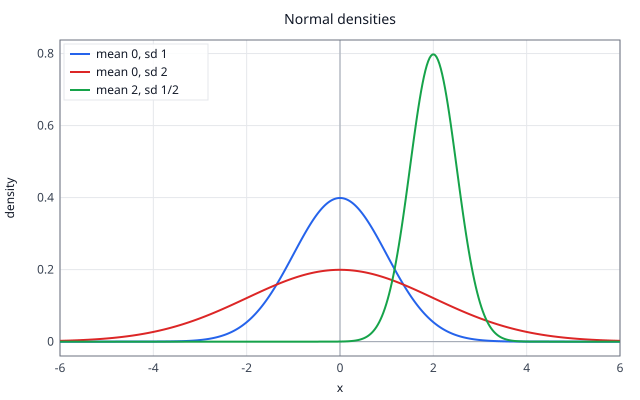

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
p = plot(normpdf(x, 0, 1), x, -6, 6);
p = show(p, plot(normpdf(x, 0, 2), x, -6, 6));
p = show(p, plot(normpdf(x, 2, 1/2), x, -6, 6));
p = legend(p, "mean 0, sd 1", "mean 0, sd 2", "mean 2, sd 1/2");
labels(title(p, "Normal densities"), "x", "density")

The area within one standard deviation of the mean is the 68% of lesson 1; within two, 95%; within three, 99.7%:

In [9]:
integrate(normpdf(x), x, -1, 1)
eval(integrate(normpdf(x), x, -1, 1))
eval(normcdf(2) - normcdf(-2))
eval(normcdf(3) - normcdf(-3))

erf(sqrt(2)/2)

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

0.6826894921370859

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.9544997361036414

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.9973002039367399

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The normal integral has no formula in elementary functions; Galileo writes it with the **error function** `erf`. The
cumulative probability $P(X \le x)$ is `normcdf(x, mu, sigma)`.

**Try this.** What fraction of a normal population lies more than 1.5 standard deviations above the mean?

## 5. Standardizing and percentiles

Any normal value can be turned into a standard one by the z-score $z = (x - \mu)/\sigma$ of lesson 1, so one table (or
one function) serves all normal distributions. With heights of mean 170 cm and standard deviation 8 cm, the fraction
of adults below 185 cm is the standard normal probability below $z = 15/8$:

In [10]:
normcdf(185, 170, 8)
normcdf(15/8)

0.9696036382347385

> Normal cumulative probability P(X ≤ x) = (1 + erf((x − μ)/(σ√2)))/2.

0.9696036382347385

> Normal cumulative probability P(X ≤ x) = (1 + erf((x − μ)/(σ√2)))/2.

97% are shorter than 185 cm. The reverse question, "how tall is the 90th percentile?", asks for the $x$ with 90% of the
area below it. `norminv(p, mu, sigma)` gives it:

In [11]:
norminv(0.9, 170, 8)
norminv(0.975)

180.25241252435683

> norminv: the value with probability 0.9 below it; z = 1.281552 standard deviations from the mean.

1.9599639845400585

> norminv: the value with probability 0.975 below it; z = 1.959964 standard deviations from the mean.

The 90th percentile is 180.3 cm. The second number, 1.96, is the standard normal value with 2.5% above it: 95% of the
area lies within 1.96 standard deviations of the mean. It will come back in every 95% confidence interval of
[lesson 6](06-estimation-and-confidence.ipynb).

**Try this.** IQ scores are normal with mean 100 and standard deviation 15. What score marks the top 2%?

## Summary

* A density $f$ is non-negative with total area 1; $P(a \le X \le b) = \int_a^b f\,dx$, and single points have
  probability 0.
* Mean $\mu = \int x f\,dx$, variance $\sigma^2 = \int (x - \mu)^2 f\,dx$.
* Uniform on $[a, b]$: flat, mean $(a + b)/2$. Exponential with mean $m$: $f = e^{-x/m}/m$, memoryless, median
  $m \log 2$.
* Normal: the bell curve; 68%, 95% and 99.7% within 1, 2 and 3 standard deviations; standardize with
  $z = (x - \mu)/\sigma$, and use `normcdf` and `norminv`.

Next: [sampling and the central limit theorem](05-sampling-and-clt.ipynb), which explains why the bell curve is
everywhere.

## Exercises

1. **A triangle.** Show that $f(x) = 2x$ on $[0, 1]$ is a density. Find its mean and $P(X > 1/2)$.
2. **Calls.** Calls arrive at a help desk with exponential gaps of mean 30 seconds. What is the probability of waiting
   more than a minute for the next call?
3. **Simulated bulbs.** With the simulated lifetimes `t`, estimate the fraction that fail before 500 hours and compare
   with 0.393.
4. **Exam scores.** Scores are normal with mean 65 and standard deviation 10. What fraction score above 80? What score
   do the top 10% exceed?
5. **Cauchy.** The density $f(x) = 1/(\pi(1 + x^2))$ has total area 1. Try to compute its mean with
   `integrate(x/(pi*(1 + x^2)), x, 0, inf)`. What goes wrong?

## Hints and answers

* **Section 1, Try this.** Both are near 0.79.
* **Section 2, Try this.** $3/10$; a mean wait of 5 minutes.
* **Section 3, Try this.** $m = 1000 \log 2 \approx 693$ hours.
* **Section 4, Try this.** `1 - normcdf(1.5)` $\approx 0.067$.
* **Section 5, Try this.** `norminv(0.98, 100, 15)` $\approx 130.8$.
* **Exercise 1.** `integrate(2*x, x, 0, 1)` is 1; the mean is $2/3$; $P(X > 1/2) = 3/4$.
* **Exercise 2.** $e^{-2} \approx 0.135$.
* **Exercise 3.** `sum(t < 500)/2000` gives $199/500 = 0.398$.
* **Exercise 4.** `1 - normcdf(80, 65, 10)` $\approx 0.067$; `norminv(0.9, 65, 10)` $\approx 77.8$.
* **Exercise 5.** Galileo reports that the integral diverges. The integral of $x/(1 + x^2)$ grows like $\tfrac12\log(1 + x^2)$ without bound: the Cauchy
  distribution has no mean.

## Sources

1. A. de Moivre, *The Doctrine of Chances*, 2nd ed., London (1738) (the normal curve as a limit of the binomial).
2. C. F. Gauss, *Theoria motus corporum coelestium*, Hamburg (1809) (the normal law of errors).
3. W. Feller, *An Introduction to Probability Theory and Its Applications*, vol. 2, 2nd ed., Wiley (1971), chapter 1.
4. S. M. Ross, *A First Course in Probability*, 9th ed., Pearson (2014), chapter 5.